## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nina Breen

**Date:** 10/12/26

In [50]:
# Your Phase 1 solution to the problem goes here.
# Q1 -1:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

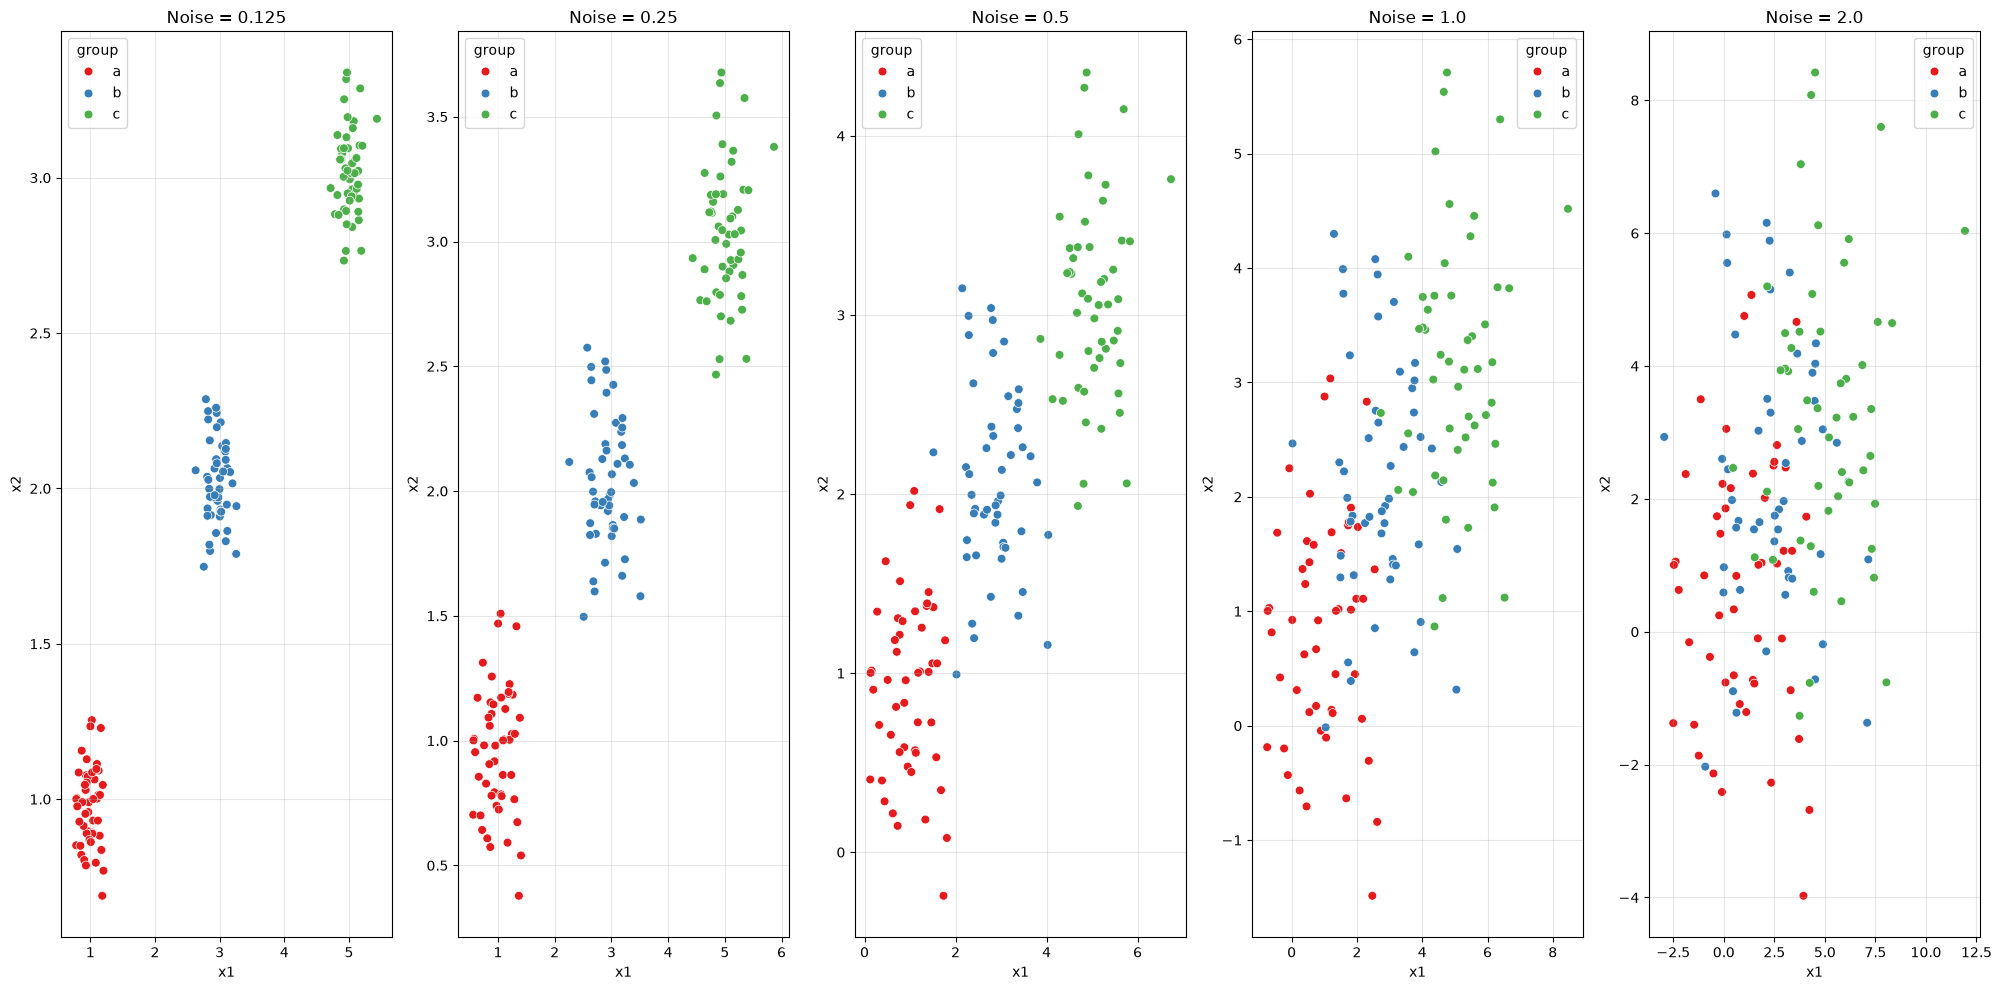

In [51]:
# Q1 -2: - making scatter plots
import matplotlib.pyplot as plt
import seaborn as sns

datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

fig, axes = plt.subplots(1, 5, figsize=(20, 10))

for i, (title, data) in enumerate(datasets.items()):
    sns.scatterplot(data=data, x='x1', y='x2', hue='group', palette='Set1', ax=axes[i], s=40)
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# As the noise level increases, the data becomes more scattered and harder to distinguish distinct clusters.


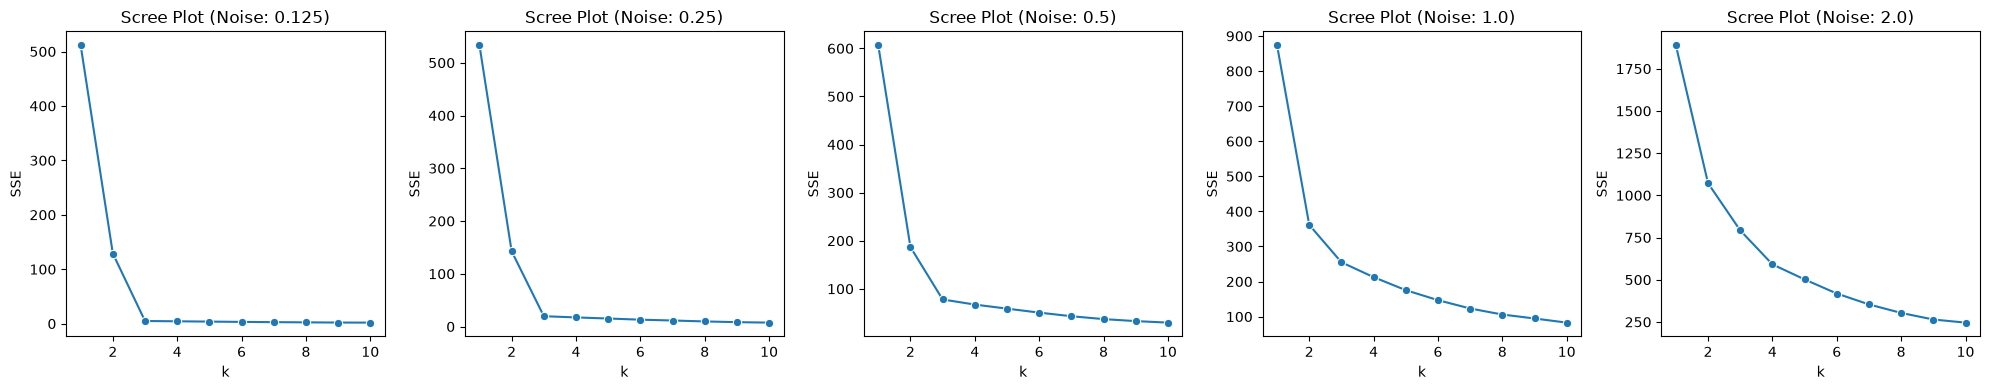

In [52]:
# Q1 - 3: - making scree plots for each dataset
from sklearn.cluster import KMeans
import seaborn as sns

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, (df, noise_level) in enumerate([(df0_125, 0.125), (df0_25, 0.25), (df0_5, 0.5), (df1_0, 1.0), (df2_0, 2.0)]):
    X = df[['x1', 'x2']]
    ks = np.arange(1, 11)
    SSE = [
        KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state=0).fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x = ks, y = SSE, ax = axes[i], marker='o')
    axes[i].set_title(f'Scree Plot (Noise: {noise_level})')
    axes[i].set_xlabel('k')
    axes[i].set_ylabel('SSE')
plt.tight_layout()
plt.show()

#As the noise level increases, the scree plot become more curved and less distinct making it harder to determine the optimal k value. 
# Additionally, the SSE values increase, indicating a poorer fit of the model to the data as the noise level increases.

# Q1 - 4: the intuition of the elbow:
# The elbow method is a technique used to determine the optimal number of clusters (k) in k-means clustering.
# It involves plotting the sum of squared errors (SSE) against the number of clusters (k). 
# The "elbow" point is where the rate of decrease in SSE sharply changes, indicating the optimal k value.
# In the example below for the noise level 0.125: I would choose k=3 as the elbow point. It is the easiest to identify the elbow point for the 0.125 compared to the other noise levels.

In [54]:
# Q2 -1: Loading, cleaning, and filtering the dataset
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df.copy() # making a copy to not override the original dataframe
df = df[df['Year'] == 2020].dropna()
display(df.info()) # this shows that there are 148 non-null values in each column and the data types make sense with column so no more data cleaning is required

<class 'pandas.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    str    
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), str(1)
memory usage: 10.5 KB


None

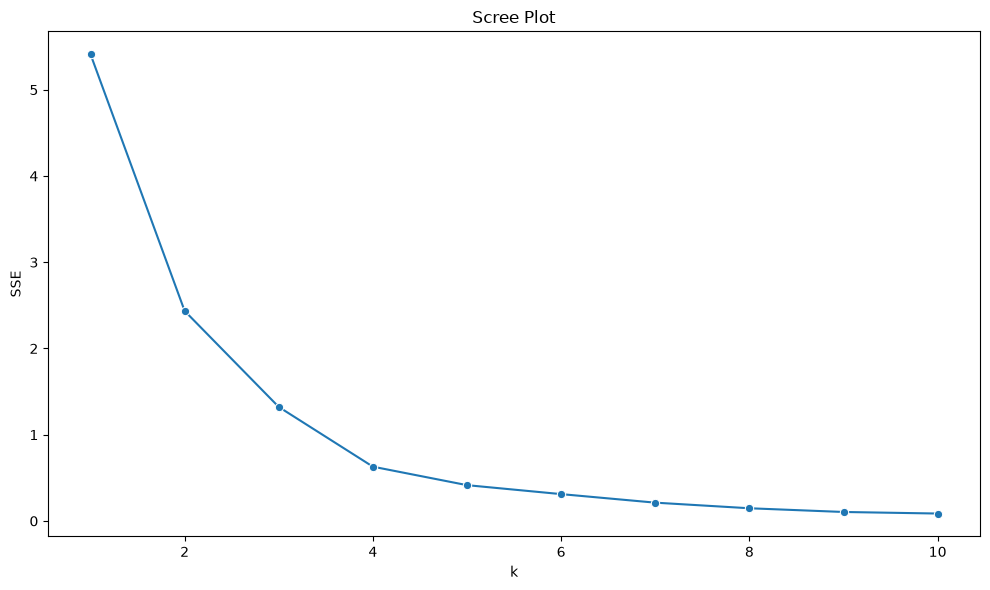

In [55]:
# Q2 -2: Performing k-means clustering on Spending and Spending per capita - max-min scaling + making scree plot to determine optimal k
from sklearn.preprocessing import MinMaxScaler

# Max-Min Scaling
scaler = MinMaxScaler()
df[['Spending (2020 USD)', 'Spending per Capita']] = scaler.fit_transform(df[['Spending (2020 USD)', 'Spending per Capita']])

# Scree Plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0)
    .fit(df[['Spending (2020 USD)', 'Spending per Capita']]).inertia_
    for k in ks
]
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x = ks, y = SSE, ax = ax, marker = 'o')
ax.set_title('Scree Plot')
ax.set_xlabel('k')
ax.set_ylabel('SSE')

plt.tight_layout()
plt.show()

# based on the scree plot, k = 4 is the optimal number of clusters based on the elbow method. This is because the rate of decrease in SSE slows down significantly after k = 4.

Cluster
2    111
0     30
1      6
3      1
Name: count, dtype: int64

Cluster                                         0            1            2  \
index                          count    30.000000     6.000000   111.000000   
                               mean   2782.600000  3783.333333  2768.540541   
                               std    1664.320688   843.766476  1665.488123   
                               min     236.000000  2582.000000    32.000000   
                               25%    1494.000000  3194.000000  1205.000000   
                               50%    2769.000000  4027.000000  2752.000000   
                               75%    4307.500000  4375.500000  4112.000000   
                               max    5506.000000  4656.000000  5880.000000   
Year                           count    30.000000     6.000000   111.000000   
                               mean   2020.000000  2020.000000  2020.000000   
                               std       0.000000     0.000000     0.000000   
                               min    2020.000000  2020.000000  2020.000000   
                               25%    2020.000000  2020.000000  2020.000000   
                               50%    2020.000000  2020.000000  2020.000000   
                               75%    2020.000000  2020.000000  2020.000000   
                               max    2020.000000  2020.000000  2020.000000   
Spending (2020 USD)            count    30.000000     6.000000   111.000000   
                               mean      0.021929     0.024968     0.006232   
                               std       0.026443     0.029370     0.032639   
                               min       0.000510     0.007820     0.000000   
                               25%       0.002936     0.009012     0.000156   
                               50%       0.007514     0.011069     0.000480   
                               75%       0.033772     0.024215     0.002940   
                               max       0.079271     0.082927     0.331409   
Percent of GDP                 count    30.000000     6.000000   111.000000   
                               mean      0.019397     0.059781     0.017349   
                               std       0.009272     0.031979     0.011699   
                               min       0.006273     0.020060     0.000054   
                               25%       0.013892     0.035460     0.010087   
                               50%       0.018834     0.059257     0.014389   
                               75%       0.022515     0.085398     0.021697   
                               max       0.042634     0.098470     0.066600   
Percent of Government Spending count    30.000000     6.000000   111.000000   
                               mean      0.045588     0.127556     0.062059   
                               std       0.030309     0.066569     0.045809   
                               min       0.011613     0.035207     0.004896   
                               25%       0.026220     0.101034     0.032496   
                               50%       0.036053     0.113271     0.048698   
                               75%       0.048819     0.164503     0.083508   
                               max       0.114776     0.225050     0.303027   
Spending per Capita            count    30.000000     6.000000   111.000000   
                               mean      0.240850     0.677089     0.031542   
                               std       0.082121     0.185083     0.033138   
                               min       0.143616     0.473454     0.000000   
                               25%       0.167325     0.560161     0.005675   
                               50%       0.229550     0.660709     0.018445   
                               75%       0.300319     0.720941     0.049530   
                               max       0.424651     1.000000     0.124462   

Cluster                                         3  
index                          count     1.000000  
                        

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,5540,2020,United States of America,1.0,0.037179,0.081976,0.933024,3


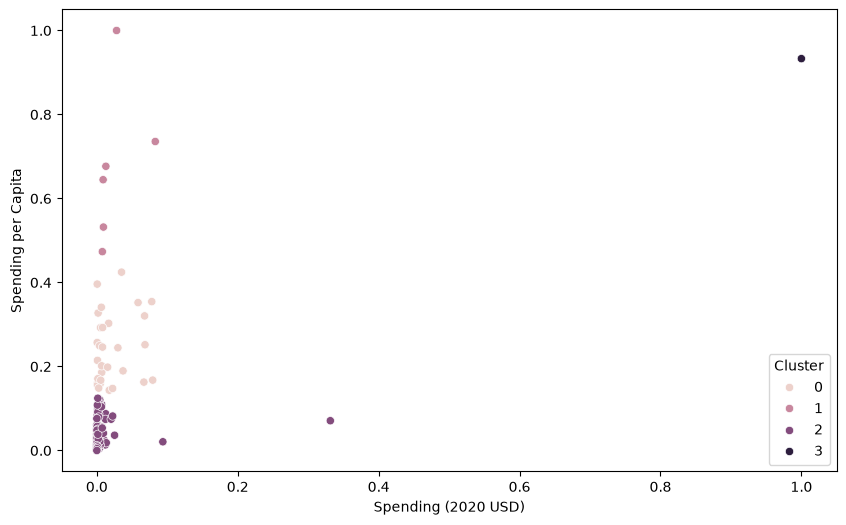

In [ ]:
# Q2 -2: Performing k-means clustering on Spending and Spending per capita - making scatter plot + computing describe table + answering questions
model = KMeans(n_clusters = 4, max_iter = 300, n_init = 10, random_state = 0)
model = model.fit(df[['Spending (2020 USD)', 'Spending per Capita']])
df['Cluster'] = model.labels_
display(df['Cluster'].value_counts())

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data = df, x = 'Spending (2020 USD)', y = 'Spending per Capita', hue = 'Cluster', ax = ax)

display(df.groupby('Cluster').describe().T)
display(df.loc[df['Country'] == 'United States of America'])

# Based on the scatterplot, most contries are near 0 with the spending (2020 USD) and vary depending on the spending per capita. 
# 3 out of 4 of the clusters seem to be placed specifically based on the spending per capita because they do not vary much in terms of total spending. 
# The US is in its own cluster because it spends significantly more than the other countries both in terms of total spending and per capita spending.

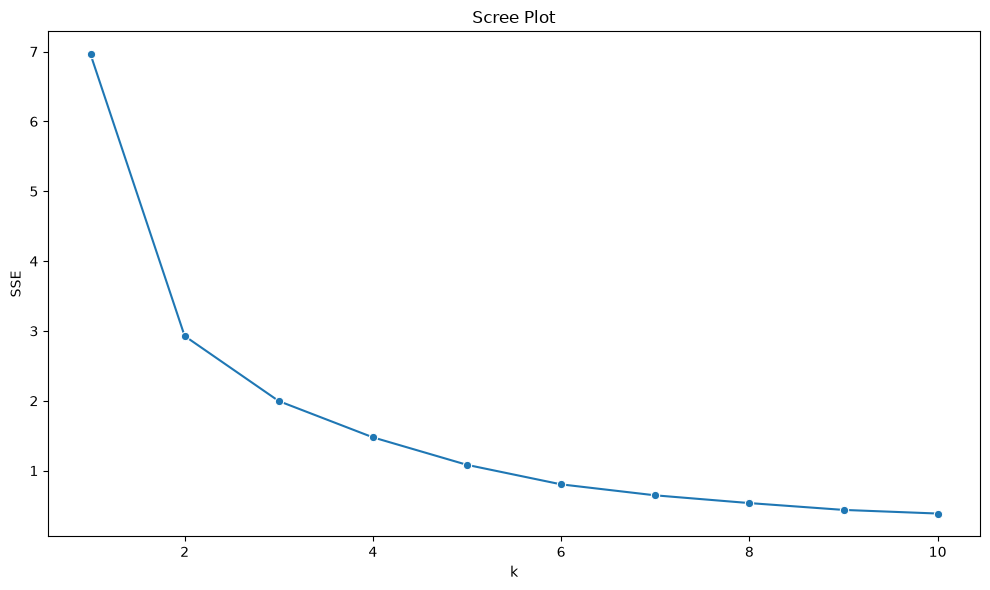

In [ ]:
# Q2 -3: Performing k-means clustering on Percent of Government Spending and Percent of GDP - max-min scaling + making scree plot to determine optimal k
from sklearn.preprocessing import MinMaxScaler

# Max-Min Scaling
scaler = MinMaxScaler()
df[['Percent of Government Spending', 'Percent of GDP']] = scaler.fit_transform(df[['Percent of Government Spending', 'Percent of GDP']])

# Scree Plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0)
    .fit(df[['Percent of Government Spending', 'Percent of GDP']]).inertia_
    for k in ks
]
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x = ks, y = SSE, ax = ax, marker = 'o')
ax.set_title('Scree Plot')
ax.set_xlabel('k')
ax.set_ylabel('SSE')

plt.tight_layout()
plt.show()

# Based on the scree plot and using the elbow method, the optimal k is 3.

Cluster
2    99
0    39
1    10
Name: count, dtype: int64

Cluster                                         0            1            2
index                          count    39.000000    10.000000    99.000000
                               mean   2894.974359  2184.200000  2871.515152
                               std    1789.517893  1773.299110  1590.144034
                               min     338.000000   100.000000    32.000000
                               25%    1052.000000   329.500000  1647.000000
                               50%    2854.000000  2650.000000  2956.000000
                               75%    4741.000000  3763.500000  4197.000000
                               max    5540.000000  4486.000000  5880.000000
Year                           count    39.000000    10.000000    99.000000
                               mean   2020.000000  2020.000000  2020.000000
                               std       0.000000     0.000000     0.000000
                               min    2020.000000  2020.000000  2020.000000
                               25%    2020.000000  2020.000000  2020.000000
                               50%    2020.000000  2020.000000  2020.000000
                               75%    2020.000000  2020.000000  2020.000000
                               max    2020.000000  2020.000000  2020.000000
Spending (2020 USD)            count    39.000000    10.000000    99.000000
                               mean      0.035173     0.016067     0.009767
                               std       0.159932     0.024879     0.035918
                               min       0.000046     0.000803     0.000000
                               25%       0.000388     0.002689     0.000145
                               50%       0.001476     0.008363     0.000718
                               75%       0.007423     0.013122     0.005012
                               max       1.000000     0.082927     0.331409
Percent of GDP                 count    39.000000    10.000000    99.000000
                               mean      0.277982     0.589502     0.128133
                               std       0.083228     0.252671     0.057728
                               min       0.114445     0.118758     0.000000
                               25%       0.215412     0.500357     0.084730
                               50%       0.281733     0.545385     0.133481
                               75%       0.329289     0.672003     0.169669
                               max       0.434443     1.000000     0.285294
Percent of Government Spending count    39.000000    10.000000    99.000000
                               mean      0.314582     0.558119     0.103582
                               std       0.080920     0.196977     0.048799
                               min       0.183219     0.311897     0.000000
                               25%       0.260067     0.436433     0.070522
                               50%       0.292315     0.547920     0.098495
                               75%       0.361373     0.584256     0.142575
                               max       0.513270     1.000000     0.233882
Spending per Capita            count    39.000000    10.000000    99.000000
                               mean      0.107422     0.324119     0.083754
                               std       0.192414     0.359100     0.110522
                               min       0.002022     0.018445     0.000000
                               25%       0.009534     0.080972     0.006313
                               50%       0.045699     0.087495     0.028409
                               75%       0.082992     0.601903     0.145673
                               max       0.933024     1.000000     0.531974

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,5540,2020,United States of America,1.0,0.377222,0.258544,0.933024,0


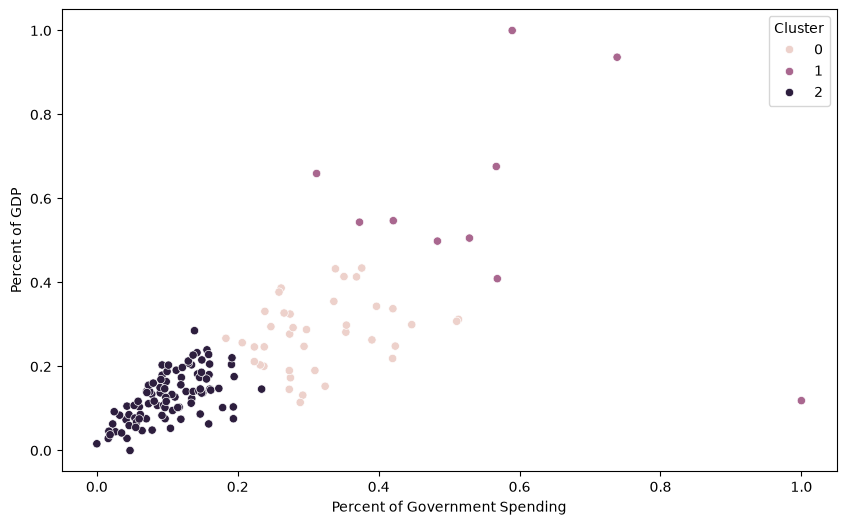

In [ ]:
# Q2 -3: Performing k-means clustering on Percent of Government Spending and Percent of GDP - making scatter plot + computing describe table + answering questions
model = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, random_state = 0)
model = model.fit(df[['Percent of Government Spending', 'Percent of GDP']])
df['Cluster'] = model.labels_
display(df['Cluster'].value_counts())

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data = df, x = 'Percent of Government Spending', y = 'Percent of GDP', hue = 'Cluster', ax = ax)

display(df.groupby('Cluster').describe().T)
display(df.loc[df['Country'] == 'United States of America'])

# What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
# There seems to be more of a linear pattern in the data. There is definitely a relationship between the two variables, and the clustering reflects 3 different segments of this linear pattern.
# Typically, as government spending increases, the percentage of GDP also tends to increase.
# The United States is in cluster 0 which is in the middle of the distribution. This is different compared to the spending pattern of the US because they were an outlier there but very much in line with the overall trend in this scatterplot.
# Comparing the 2 scatter plots, there is an obvious relationship with the government spending and GDP variables, while the total spending and per capita spending shows a but clump and one extreme outlier which could be influencing the clustering and relationship results.


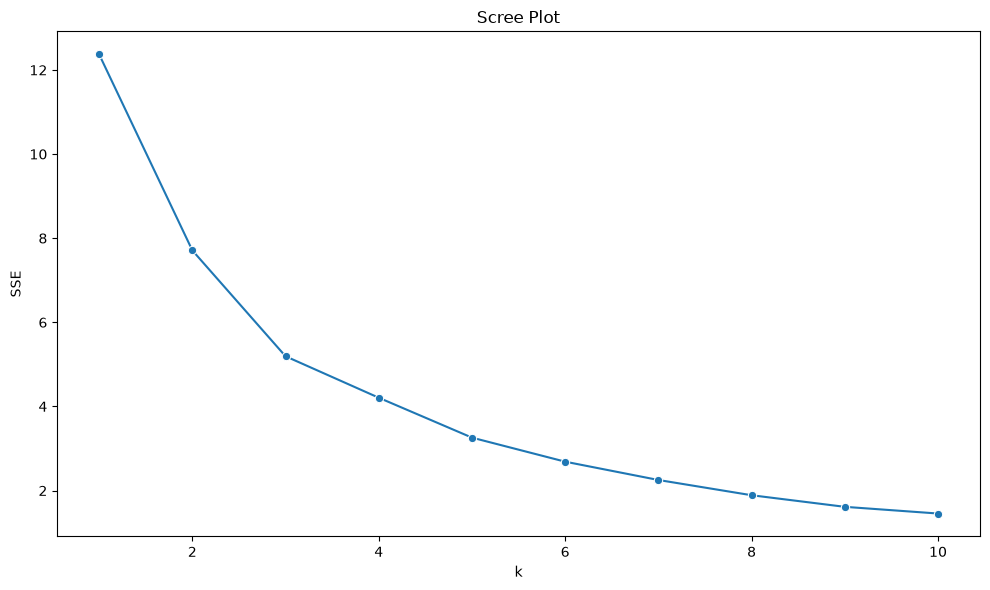

In [66]:
# Q2 - 4: using clustering with all 4 variables - making scree plot to determine k value
features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

df[features] = scaler.fit_transform(df[features])


ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0)
    .fit(df[features]).inertia_
    for k in ks
]
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x = ks, y = SSE, ax = ax, marker = 'o')
ax.set_title('Scree Plot')
ax.set_xlabel('k')
ax.set_ylabel('SSE')

plt.tight_layout()
plt.show()

# k = 3 base on the scree plot


Cluster
0    111
1     31
2      6
Name: count, dtype: int64

Cluster                                         0            1            2
index                          count   111.000000    31.000000     6.000000
                               mean   2854.918919  2512.903226  4038.333333
                               std    1618.183489  1789.866352  1113.917352
                               min      32.000000   100.000000  2582.000000
                               25%    1545.000000   780.000000  3202.500000
                               50%    2888.000000  2514.000000  4265.000000
                               75%    4231.000000  3721.000000  4613.500000
                               max    5880.000000  5438.000000  5540.000000
Year                           count   111.000000    31.000000     6.000000
                               mean   2020.000000  2020.000000  2020.000000
                               std       0.000000     0.000000     0.000000
                               min    2020.000000  2020.000000  2020.000000
                               25%    2020.000000  2020.000000  2020.000000
                               50%    2020.000000  2020.000000  2020.000000
                               75%    2020.000000  2020.000000  2020.000000
                               max    2020.000000  2020.000000  2020.000000
Spending (2020 USD)            count   111.000000    31.000000     6.000000
                               mean      0.009093     0.011276     0.190080
                               std       0.034018     0.022999     0.397790
                               min       0.000000     0.000198     0.007820
                               25%       0.000156     0.000590     0.009882
                               50%       0.000718     0.001794     0.020413
                               75%       0.005012     0.009931     0.069200
                               max       0.331409     0.093692     1.000000
Percent of GDP                 count   111.000000    31.000000     6.000000
                               mean      0.135799     0.339761     0.635867
                               std       0.060929     0.116334     0.287303
                               min       0.000000     0.118758     0.298475
                               25%       0.089606     0.279489     0.418816
                               50%       0.137524     0.324845     0.601553
                               75%       0.180003     0.411280     0.867175
                               max       0.285294     0.676168     1.000000
Percent of Government Spending count   111.000000    31.000000     6.000000
                               mean      0.118920     0.396096     0.437575
                               std       0.064803     0.147343     0.185799
                               min       0.000000     0.238514     0.258544
                               25%       0.073176     0.295832     0.322469
                               50%       0.110877     0.368563     0.363513
                               75%       0.152983     0.435269     0.535359
                               max       0.292315     1.000000     0.738448
Spending per Capita            count   111.000000    31.000000     6.000000
                               mean      0.077921     0.084176     0.743931
                               std       0.106273     0.102326     0.194379
                               min       0.000000     0.007031     0.473454
                               25%       0.005675     0.018218     0.652714
                               50%       0.026392     0.053528     0.706194
                               75%       0.116959     0.086020     0.883690
                               max       0.531974     0.396213     1.000000

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,5540,2020,United States of America,1.0,0.377222,0.258544,0.933024,2


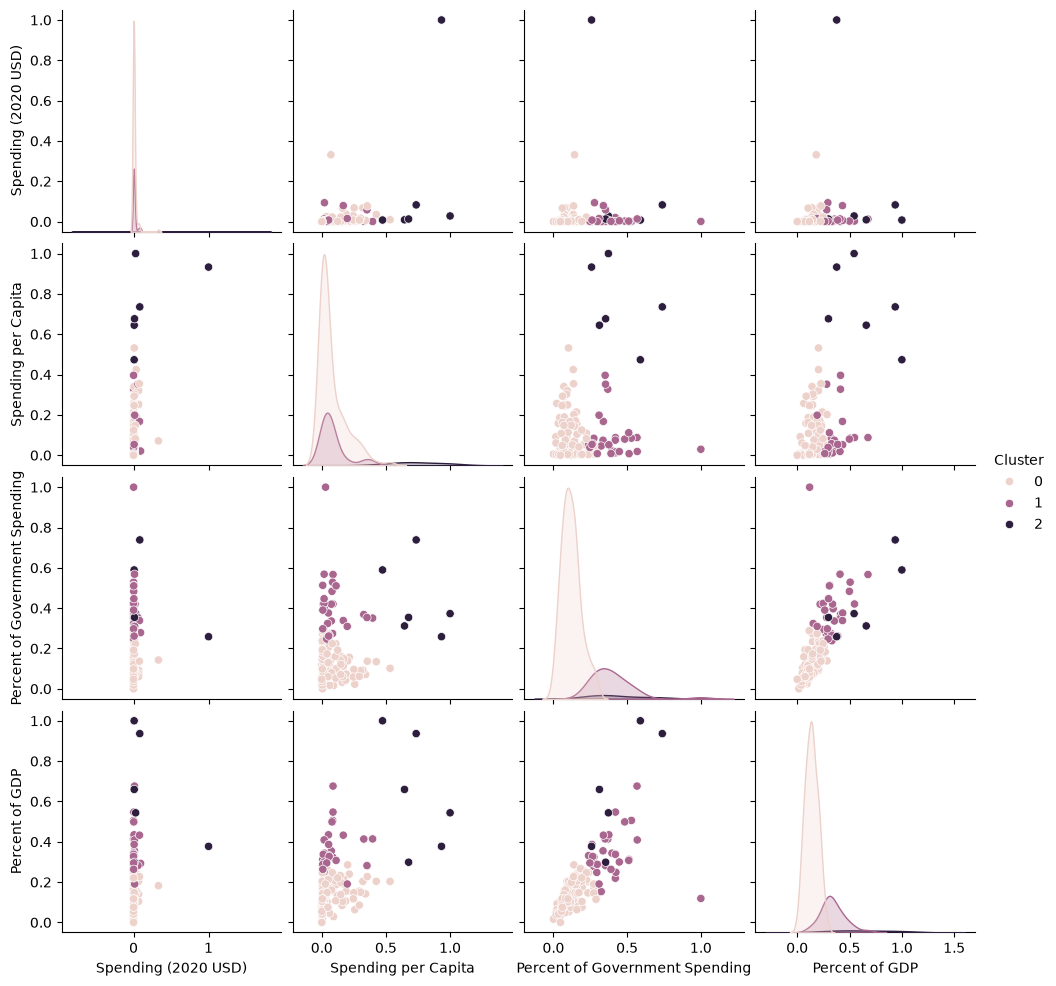

In [ ]:
# Q2 - 4: using clustering with all 4 variables - making plot with all 4 variables and clustering
model = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, random_state = 0)
model = model.fit(df[features])
df['Cluster'] = model.labels_
display(df['Cluster'].value_counts())

sns.pairplot(data = df, vars = features, hue = 'Cluster')

display(df.groupby('Cluster').describe().T)
display(df.loc[df['Country'] == 'United States of America'])

# It seems that the clusters are pretty similar to what you would expect with the combination between all 4 values. 
# Based on the pairplots, the clusters are distinguishable in basically all of the plots. The only plot that seems that the clusters are not really different are the ones that have to do withspenind (2020 USD)
# This shows that the spending is hard to cluster on, but the other variables create clusters. 

# Q2 - 5: useful patterns
# The clustering did show useful a useful pattern. It basically clustered the countries based on their spending and how well off the countries are.
# Using this method for spending analysis is helpful when looking at specific spending (government and per captia), but not helpful when looking at the overall spending.
# This is due to an outlier and a large limitation to this model is that an outlier can really influence the results. 
# This is shown with the spending (2020 USD) variable because the outlier really influenced the scaling leading to a lack of relationship shown.



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** a0a7aed4541cabc171efe855a7ca66d967a18759
- **AI tool and model used:** Claude Sonent

### *Prompts used

1. Attached is my Jupyter Notebook data science intro to machine learning assignment. Can you go through my work and check that it is correct, and give any feedback/ any changes you recommend? Go through both questions and all the subparts of each. 
When giving the changes, show me what you want to change, what you want to change it to, and why you want to change it.
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. 1.2: scatterplots

Change:

python
fig, axes = plt.subplots(1, 5, figsize=(20, 10))

To:

python
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)

Why: Each panel currently has its own axis range. At noise 0.125 the axes zoom in so tightly that the clusters look spread out, which hides how much tighter they really are than at noise 2.0. Shared axes make the comparison honest. A 1×5 grid at height 10 also makes tall, skinny panels.

Comment change: Your comment (“more scattered and harder to distinguish”) is right but vague. Make it specific:

At 0.125 and 0.25 the three groups are cleanly separated. At 0.5 groups b and c start to touch. At 1.0 all three overlap substantially. At 2.0 they look like one cloud, and the colors are the only reason you know there are three groups.
2. 1.3: scree plots

Change: Add sharey=True to plt.subplots(1, 5, ...), or put all five curves on one canvas:

python
fig, ax = plt.subplots(figsize=(8, 5))
for title, data in datasets.items():
    X = data[['x1', 'x2']]
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    ax.plot(ks, SSE, marker='o', label=title)
ax.set_xlabel('k'); ax.set_ylabel('SSE'); ax.legend()

Why: The prompt says to watch the vertical axis. Your y-axes run from ~500 to ~1750 across plots, so every curve looks like it fills its own panel.

Comment change: Replace “the scree plot becomes more curved” and “SSE increases, indicating a poorer fit” with:

At 0.125 there’s a sharp elbow at k=3, after which SSE is essentially flat. The elbow is still visible at 0.25 and 0.5 but softer. At 1.0 it’s ambiguous (2 or 3?), and at 2.0 the curve is smooth with no clear elbow, so I couldn’t definitively pick k.

Why: “Poorer fit” is misleading. SSE is higher mainly because noisier data has more variance around any set of centers. The real effect of noise is that the elbow disappears.
3. 1.4: elbow intuition

Your answer defines the elbow method but doesn’t use the simulation, and it says “the example below” when there isn’t one.

Change to something like:

SSE always falls as k rises (at k = n it’s zero), so we can’t just minimize it. We look for where adding a cluster stops buying much. Here the data truly has 3 clusters. Going from k=1→2→3 each splits apart real groups, so SSE drops a lot (about 510 → 125 → 5 at noise 0.125). Past k=3, extra clusters just cut up groups that are already tight, so SSE barely moves. That bend is the elbow. With noise 2.0 the groups overlap, so no k captures real structure and the curve declines smoothly.
4. 2.1: cleaning

Change:

python
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df.copy() # making a copy to not override the original dataframe
df = df[df['Year'] == 2020].dropna()
display(df.info())

To:

python
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()
df = df.drop(columns=['index'])      # leftover row-index column, not a real variable
df.info()                             # no display() — it prints a stray "None"
print(df['Country'].is_unique)

Why:

Your info() output shows a column literally named index. It’s an artifact of the CSV and isn’t a variable. It also pollutes every describe() table later, where it shows up as a row of numbers.
Year is constant (2020) after filtering, so it’s also noise in the describe tables.
The .copy() right after read_csv does nothing, since read_csv already returns a new object. It’s more useful after filtering.
Your conclusion that dtypes look fine is correct. But I can’t see the CSV, so if your instructor expected something specific (e.g., non-country rows), check the Country values.
5. 2.2: Spending & Spending per Capita

Change (scaling):

python
df[['Spending (2020 USD)', 'Spending per Capita']] = scaler.fit_transform(df[[...]])

To:

python
cols2 = ['Spending (2020 USD)', 'Spending per Capita']
X2 = pd.DataFrame(MinMaxScaler().fit_transform(df[cols2]), columns=cols2, index=df.index)
# use X2 in the scree plot and in KMeans.fit(X2)

Why: Overwriting df means your describe tables show scaled values (e.g., 0.33) rather than dollars, which makes them hard to interpret. It also means Q2.4 re-scales columns that were already scaled. That happens to be harmless (min-max is idempotent), but only by luck.

Change (plot colors): add palette='Set1' to sns.scatterplot.
Why: Clusters 0 and 1 are two nearly identical pinks in the default sequential palette.

Change (factual error in your comment):

“The US is in its own cluster because it spends significantly more… both in terms of total spending and per capita spending.”

To:

The US is alone in cluster 3 because of total spending: it’s at 1.0, and the next largest (≈0.33, likely China, worth confirming) is far below. Its per capita spending (0.93) is very high but not the maximum; a smaller country sits at 1.0.

Why: Your own output shows US per capita = 0.933, and the scatterplot shows a point at 1.0.

Add: the answer to “patterns in cluster membership” needs actual countries:

python
df.groupby('Cluster')['Country'].apply(list)

Then say what you see. For example, cluster 1 (6 countries) has high per capita but small total spending, and cluster 2 (111 countries) is everyone low on both. Also note that China sits in the big low-spending cluster, a notable consequence of the US outlier squashing everyone else toward 0 on the x-axis.

Change (describe table): df.groupby('Cluster').describe().T → df.groupby('Cluster')[cols2].describe().T, so it isn’t cluttered with index and Year.

Scree k=4: Defensible, though k=3 is also plausible (the curve bends gradually). Add one sentence acknowledging that it’s a judgment call.
6. 2.3: Percent of Govt Spending & Percent of GDP
Scree k=3: The steepest drop is 1→2, so the elbow could be 2 or 3. Say that, then justify 3.
Wording fix: “as government spending increases, the percentage of GDP also increases” misreads the variable. It’s the share of the government budget going to the military. Better: “Countries that devote a larger share of their budget to the military also devote a larger share of GDP to it.” A correlation (df[[...]].corr()) would back up “obvious relationship.”
Comparison to part 2: Make it explicit. Here both variables are ratios, so no single country dominates the way the US did, and the clusters are roughly low/medium/high “burden.” The US goes from an isolated outlier to the middle cluster. The same country looks extreme or ordinary depending on which variables you pick.
Missed observation: There’s a point at (1.0, ~0.12) in cluster 1, the highest share of government spending but low share of GDP. Name that country.
Typos: “but clump” → “big clump”.
7. 2.4: all four variables

Change: df[features] = scaler.fit_transform(df[features]) → build a fresh scaled frame from the original columns (same pattern as 2.2).
Why: As noted above, it only works because min-max is idempotent.

Expand the comments. “k = 3 base on the scree plot” is one line. Justify it, as the curve is smooth (elbow at 2–4 is arguable). “Pretty similar to what you would expect” doesn’t compare anything. Use your outputs:

Clusters have 111/31/6 countries. The US lands in the 6-country cluster with the highest Percent of GDP (mean ≈0.64 scaled), versus alone in Part 2 and the middle cluster in Part 3. The pairplot shows the clusters separate well on the three non-total-spending variables but overlap on Spending (2020 USD), which is because only the US and one other country have non-trivial values after min-max scaling.

Also fix “withspenind” and “that seems that.”
8. 2.5: usefulness
Unsupported claim: “clustered countries based on… how well off the countries are.” None of your variables measures wealth. Per capita spending correlates with wealth, but it also reflects security threats. Rephrase as “countries with a high military burden and high per capita spending,” and check the cluster members before saying more.
Refine your conclusion: “not helpful for overall spending” is a bit off. The real problem is that spending is extremely right-skewed, so min-max scaling lets the US dominate. A log transform before scaling is the standard fix. I’d mention it as a possible next step even if the assignment requires min-max.
Your outlier-sensitivity point is a strong insight. Keep it, and tie it to the 1-country cluster in Q2.2.
Typos: “useful a useful,” “captia.”

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The AI is just changing my wording and making the graph look better but not changing anything of real importance to the question. I do like how they suggest the scatterplot should be formatted so I made those changes. |
| 2 | modify | It recommends to make all the scree plots on one graph, but I want to keep them seperate. I will add the sharey = True to standardize the axis. I will also add the explanation they have ebcause it is more specific and adds more detail to my responce. Also I agree that saying 'poorer fit' was not the correct wording in this situation so I removed that sentence.|
| 3 | modify | Adding to my explanation of the elbow method. I think my analysis is correct, but adding certain details strengthens the response. |
| 4 | Accept | I think removing the index column is helpful because it makes the describe tables later on more legible. Additionally, making sure that there are all unique country names is an important thing to check and good practice even though the data was already completely clean with the way I did it. |
| 5 | Accept | I did not think of the fact that by modeling straight with the dataframe it was overriding what we had and the describe tables was messed up. I like what it suggested to fix this problem. I also agree that the colors are hard to differentiate so I will also be making that change. The other suggestions are more cosmetic for the code and I will be doing them because they make it look better. I will also be changing the color and the scaling in the other plots too to make the clusters more noticable. |
| 6 | reject | I think this is not really relevant to the question and it is just saying to add more detail, but I think what I have is enough. |
| 7 | Accept | I am going to do the same as the changes in part 5. Also, I think their comment is more descriptive and better than what I had. |
| 8 | Accept | It points out very helpful analysis about what the queston is actually asking for. I just think it states the usefulness better than I did. I did not realize that military spending had to do with this, so my explanation is a bit wrong |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [71]:
# Your Phase 1 solution to the problem goes here.
# Q1 -1:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


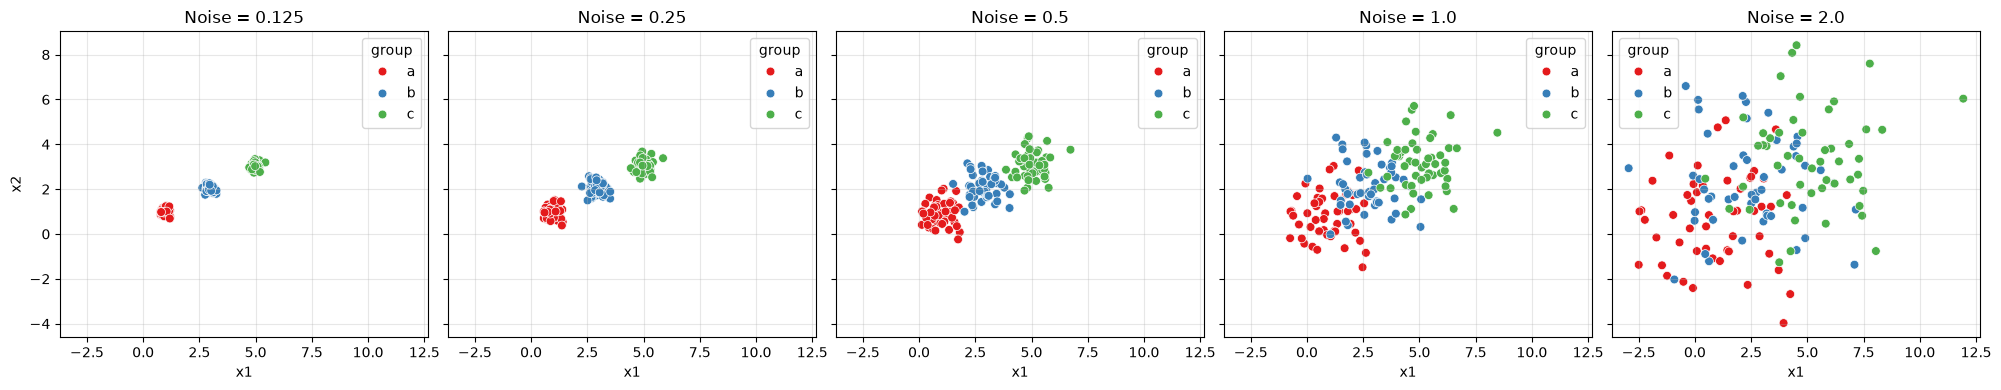

In [ ]:
# Q1 -2: - making scatter plots
import matplotlib.pyplot as plt
import seaborn as sns

datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)

for i, (title, data) in enumerate(datasets.items()):
    sns.scatterplot(data=data, x='x1', y='x2', hue='group', palette='Set1', ax=axes[i], s=40)
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# As the noise level increases, the data becomes more scattered and harder to distinguish distinct clusters.
# At 0.125 and 0.25 the three groups are cleanly separated. At 0.5 groups b and c start to touch. At 1.0 all three overlap substantially. At 2.0 they look like one cloud, and the colors are the only reason you know there are three groups.


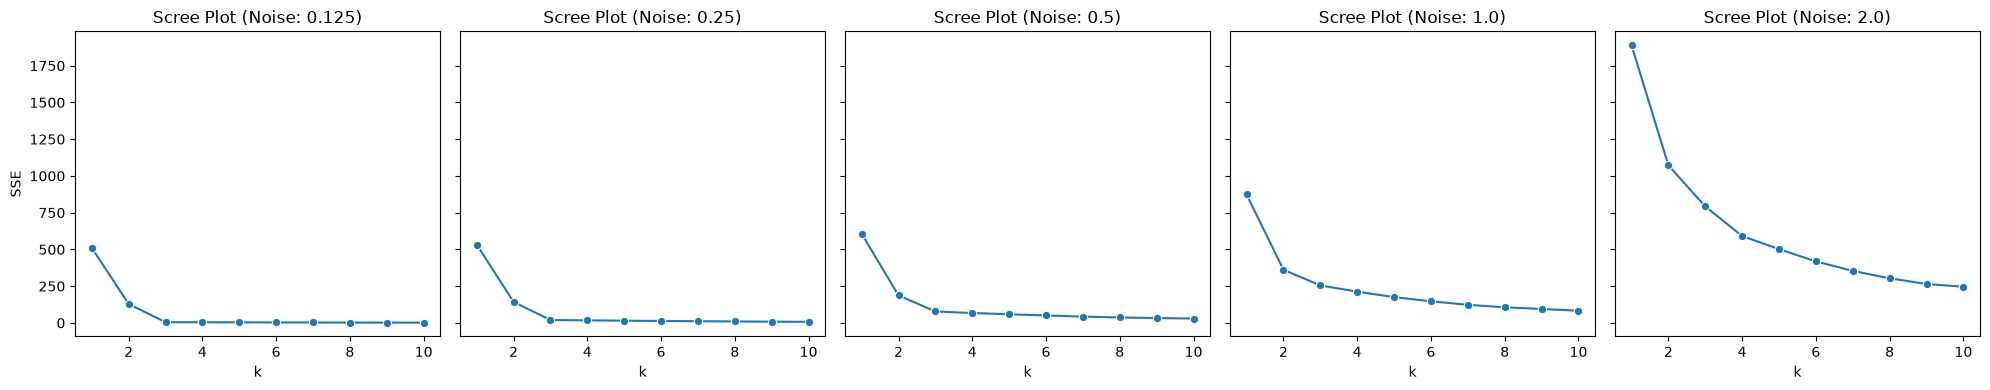

In [74]:
# Q1 - 3: - making scree plots for each dataset
from sklearn.cluster import KMeans
import seaborn as sns

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, (df, noise_level) in enumerate([(df0_125, 0.125), (df0_25, 0.25), (df0_5, 0.5), (df1_0, 1.0), (df2_0, 2.0)]):
    X = df[['x1', 'x2']]
    ks = np.arange(1, 11)
    SSE = [
        KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state=0).fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x = ks, y = SSE, ax = axes[i], marker='o')
    axes[i].set_title(f'Scree Plot (Noise: {noise_level})')
    axes[i].set_xlabel('k')
    axes[i].set_ylabel('SSE')
plt.tight_layout()
plt.show()

#As the noise level increases, the scree plot become more curved and less distinct making it harder to determine the optimal k value. 
#  At 0.125 there’s a sharp elbow at k=3, after which SSE is essentially flat. The elbow is still visible at 0.25 and 0.5 but softer. At 1.0 it’s ambiguous (2 or 3?), and at 2.0 the curve is smooth with no clear elbow, so I couldn’t definitively pick k.

# Q1 - 4: the intuition of the elbow:
# The elbow method is a technique used to determine the optimal number of clusters (k) in k-means clustering.
# It involves plotting the sum of squared errors (SSE) against the number of clusters (k). 
# The "elbow" point is where the rate of decrease in SSE sharply changes, indicating the optimal k value.
# SSE always falls as k rises (at k = n it’s zero), so we can’t just minimize it. We look for where adding a cluster stops buying much.
# In the example below for the noise level 0.125: I would choose k=3 as the elbow point. It is the easiest to identify the elbow point for the 0.125 compared to the other noise levels.
# With noise 2.0 the groups overlap, so no k captures real structure and the curve declines smoothly.

In [76]:
# Q2 -1: Loading, cleaning, and filtering the dataset
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()
df = df.drop(columns = ['index'])
display(df.info()) # this shows that there are 148 non-null values in each column and the data types make sense with column so no more data cleaning is required
print(df['Country'].is_unique)

<class 'pandas.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            148 non-null    int64  
 1   Country                         148 non-null    str    
 2   Spending (2020 USD)             148 non-null    float64
 3   Percent of GDP                  148 non-null    float64
 4   Percent of Government Spending  148 non-null    float64
 5   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 9.3 KB


None

True


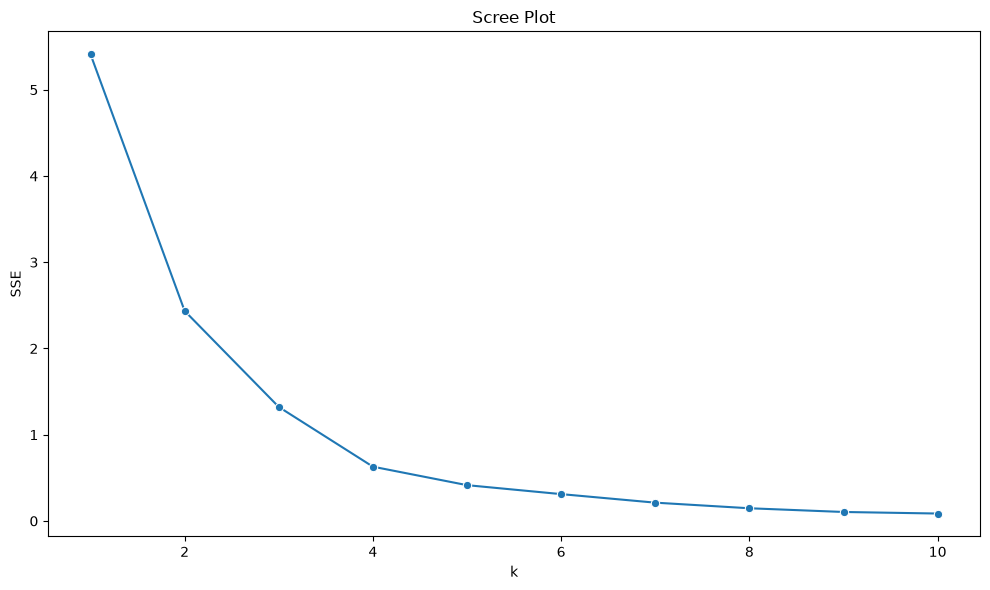

In [77]:
# Q2 -2: Performing k-means clustering on Spending and Spending per capita - max-min scaling + making scree plot to determine optimal k
from sklearn.preprocessing import MinMaxScaler

# Max-Min Scaling
scaler = MinMaxScaler()
cols2 = ['Spending (2020 USD)', 'Spending per Capita']
X2 = pd.DataFrame(MinMaxScaler().fit_transform(df[cols2]), columns=cols2, index=df.index)

# Scree Plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0)
    .fit(X2).inertia_
    for k in ks
]
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x = ks, y = SSE, ax = ax, marker = 'o')
ax.set_title('Scree Plot')
ax.set_xlabel('k')
ax.set_ylabel('SSE')

plt.tight_layout()
plt.show()

# based on the scree plot, k = 4 is the optimal number of clusters based on the elbow method. This is because the rate of decrease in SSE slows down significantly after k = 4.

Cluster
2    111
0     30
1      6
3      1
Name: count, dtype: int64

Cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.880549   
                    50%      579.004604   1665.447478      47.056944   
                    75%      757.328513   1817.219993     125.387558   
                    max     1070.623322   2520.398541     314.201312   

Cluster                                3  
Spending (2020 USD) count       1.000000  
                    mean   778397.200000  
                    std              NaN  
                    min    778397.200000  
                    25%    778397.200000  
                    50%    778397.200000  
                    75%    778397.200000  
                    max    778397.200000  
Spending per Capita count       1.000000  
                    mean     2351.631858  
                    std              NaN  
                    min      2351.631858  
                    25%      2351.631858  
                    50%      2351.631858  
                    75%      2351.631858  
                    max      2351.631858

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3


Cluster
0    [Australia, Austria, Bahrain, Belgium, Brunei,...
1    [Israel, Kuwait, Norway, Oman, Saudi Arabia, S...
2    [Afghanistan, Albania, Algeria, Angola, Argent...
3                           [United States of America]
Name: Country, dtype: object

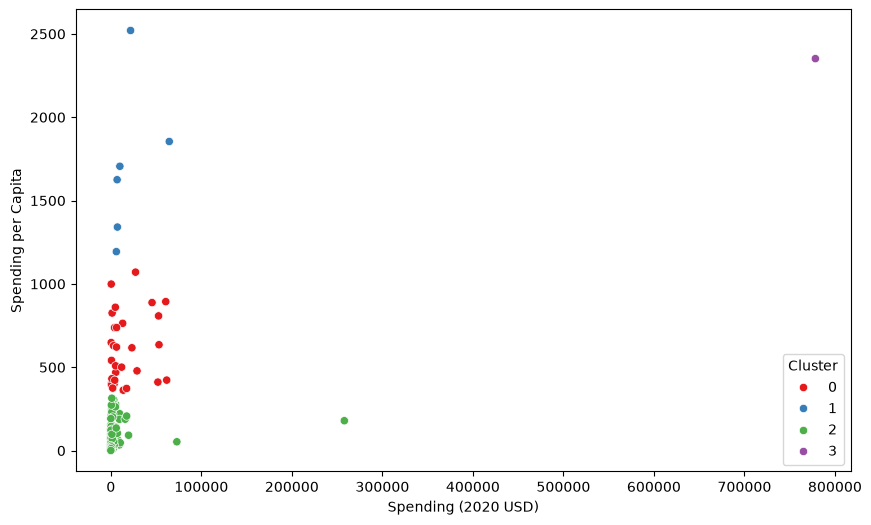

In [ ]:
# Q2 -2: Performing k-means clustering on Spending and Spending per capita - making scatter plot + computing describe table + answering questions
model = KMeans(n_clusters = 4, max_iter = 300, n_init = 10, random_state = 0)
model = model.fit(X2)
df['Cluster'] = model.labels_
display(df['Cluster'].value_counts())

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data = df, x = 'Spending (2020 USD)', y = 'Spending per Capita', hue = 'Cluster', palette = 'Set1', ax = ax)

display(df.groupby('Cluster')[cols2].describe().T)
display(df.loc[df['Country'] == 'United States of America'])
display(df.groupby('Cluster')['Country'].apply(list))

# Based on the scatterplot, most contries are near 0 with the spending (2020 USD) and vary depending on the spending per capita. 
# 3 out of 4 of the clusters seem to be placed specifically based on the spending per capita because they do not vary much in terms of total spending. 
# The US is in its own cluster because it spends significantly more than the other countries both in terms of total spending and per capita spending (execpt for one country that spends more with the per capita spending).

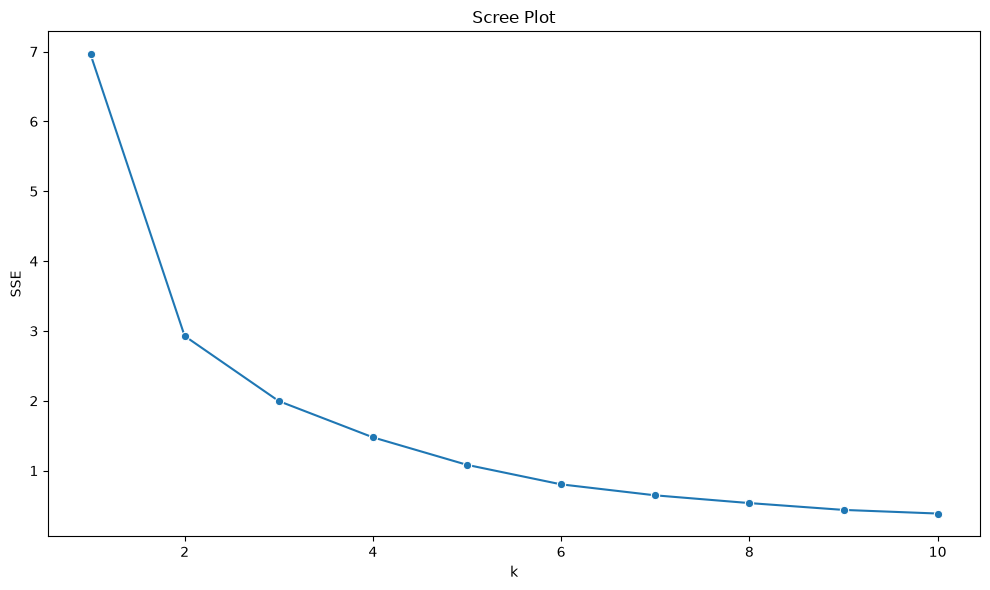

In [80]:
# Q2 -3: Performing k-means clustering on Percent of Government Spending and Percent of GDP - max-min scaling + making scree plot to determine optimal k
from sklearn.preprocessing import MinMaxScaler

# Max-Min Scaling
scaler = MinMaxScaler()
cols3 = ['Percent of Government Spending', 'Percent of GDP']
X3 = pd.DataFrame(MinMaxScaler().fit_transform(df[cols3]), columns=cols3, index=df.index)

# Scree Plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0)
    .fit(X3).inertia_
    for k in ks
]
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x = ks, y = SSE, ax = ax, marker = 'o')
ax.set_title('Scree Plot')
ax.set_xlabel('k')
ax.set_ylabel('SSE')

plt.tight_layout()
plt.show()

# Based on the scree plot and using the elbow method, the optimal k is 3.

Cluster
2    99
0    39
1    10
Name: count, dtype: int64

Cluster                                       0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.314582   0.558119   0.103582
                               std     0.080920   0.196977   0.048799
                               min     0.183219   0.311897   0.000000
                               25%     0.260067   0.436433   0.070522
                               50%     0.292315   0.547920   0.098495
                               75%     0.361373   0.584256   0.142575
                               max     0.513270   1.000000   0.233882
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.277982   0.589502   0.128133
                               std     0.083228   0.252671   0.057728
                               min     0.114445   0.118758   0.000000
                               25%     0.215412   0.500357   0.084730
                               50%     0.281733   0.545385   0.133481
                               75%     0.329289   0.672003   0.169669
                               max     0.434443   1.000000   0.285294

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,2020,United States of America,778397.2,0.377222,0.258544,2351.631858,0


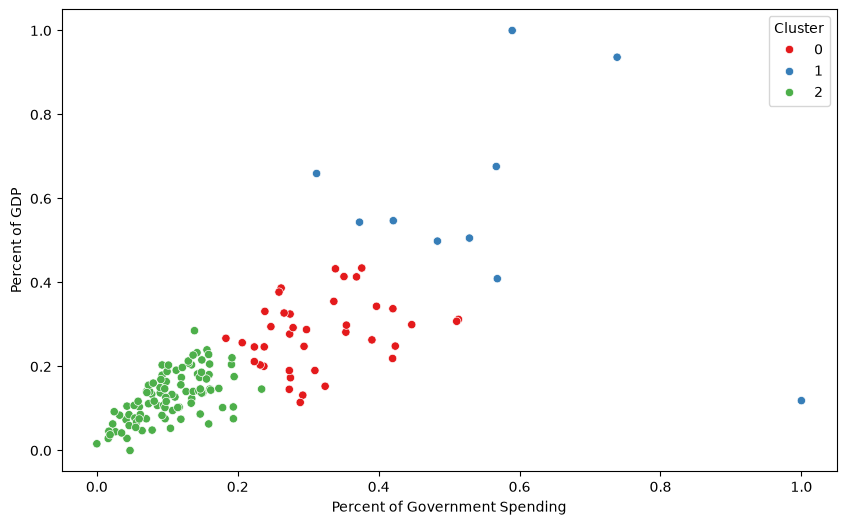

In [ ]:
# Q2 -3: Performing k-means clustering on Percent of Government Spending and Percent of GDP - making scatter plot + computing describe table + answering questions
model = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, random_state = 0)
model = model.fit(X3)
df['Cluster'] = model.labels_
display(df['Cluster'].value_counts())

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data = df, x = 'Percent of Government Spending', y = 'Percent of GDP', hue = 'Cluster', palette = 'Set1', ax = ax)

display(df.groupby('Cluster')[cols3].describe().T)
display(df.loc[df['Country'] == 'United States of America'])

# What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
# There seems to be more of a linear pattern in the data. There is definitely a relationship between the two variables, and the clustering reflects 3 different segments of this linear pattern.
# Typically, as government spending increases, the percentage of GDP also tends to increase.
# The United States is in cluster 0 which is in the middle of the distribution. This is different compared to the spending pattern of the US because they were an outlier there but very much in line with the overall trend in this scatterplot.
# Comparing the 2 scatter plots, there is an obvious relationship with the government spending and GDP variables, while the total spending and per capita spending shows a big clump and one extreme outlier which could be influencing the clustering and relationship results.


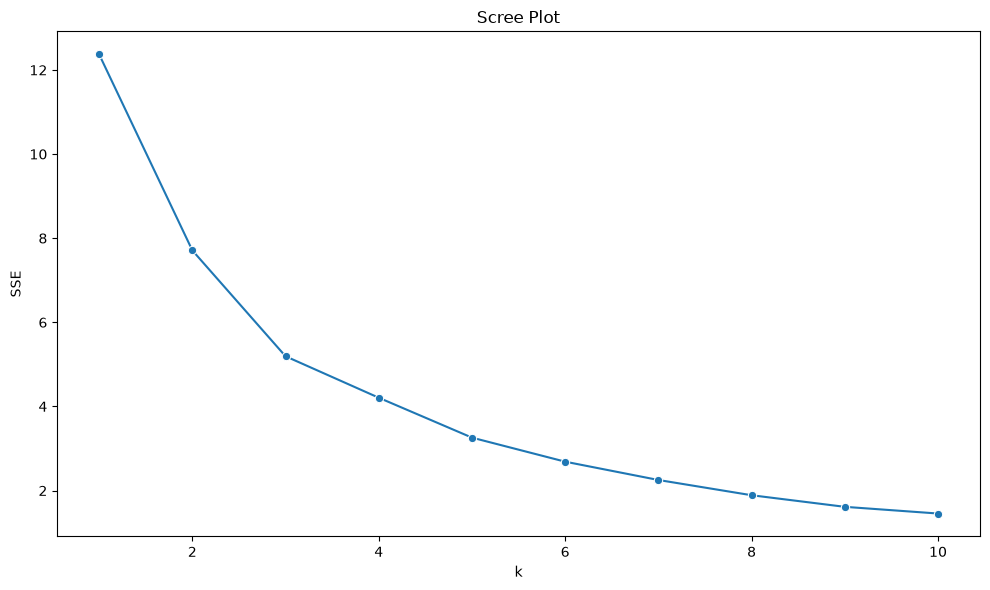

In [82]:
# Q2 - 4: using clustering with all 4 variables - making scree plot to determine k value
cols4 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

X4 = pd.DataFrame(MinMaxScaler().fit_transform(df[cols4]), columns=cols4, index=df.index)


ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0)
    .fit(X4).inertia_
    for k in ks
]
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x = ks, y = SSE, ax = ax, marker = 'o')
ax.set_title('Scree Plot')
ax.set_xlabel('k')
ax.set_ylabel('SSE')

plt.tight_layout()
plt.show()

# k = 3 base on the scree plot


Cluster
0    111
1     31
2      6
Name: count, dtype: int64

Cluster                                           0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%        67.083417    135.459845   
                               75%       295.296094    217.333791   
                               max      1341.058851    998.966186   
Percent of Government Spending count     111.000000     31.000000   
                               mean        0.118920      0.396096   
                               std         0.064803      0.147343   
                               min         0.000000      0.238514   
                               25%         0.073176      0.295832   
                               50%         0.110877      0.368563   
                               75%         0.152983      0.435269   
                               max         0.292315      1.000000   
Percent of GDP                 count     111.000000     31.000000   
                               mean        0.135799      0.339761   
                               std         0.060929      0.116334   
                               min         0.000000      0.118758   
                               25%         0.089606      0.279489   
                               50%         0.137524      0.324845   
                               75%         0.180003      0.411280   
                               max         0.285294      0.676168   

Cluster                                           2  
Spending (2020 USD)            count       6.000000  
                               mean   147964.582042  
                               std    309635.189564  
                               min      6095.708713  
                               25%      7700.424616  
                               50%     15897.570598  
                               75%     53872.942442  
                               max    778397.200000  
Spending per Capita            count       6.000000  
                               mean     1875.150751  
                               std       489.800206  
                               min      1193.598730  
                               25%      1645.301864  
                               50%      1780.059564  
                               75%      2227.318999  
                               max      2520.398541  
Percent of Government Spending count       6.000000  
                               mean        0.437575  
                               std         0.185799  
                               min         0.258544  
                               25%         0.322469  
                               50%         0.363513  
                               75%         0.535359  
                               max         0.738448  
Percent of GDP                 count       6.000000  
                               mean        0.635867  
                               std         0.287303  
                               min         0.298475  
                               25%         0.418816  
                               50%         0.601553  
                               75%         0.867

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,2020,United States of America,778397.2,0.377222,0.258544,2351.631858,2


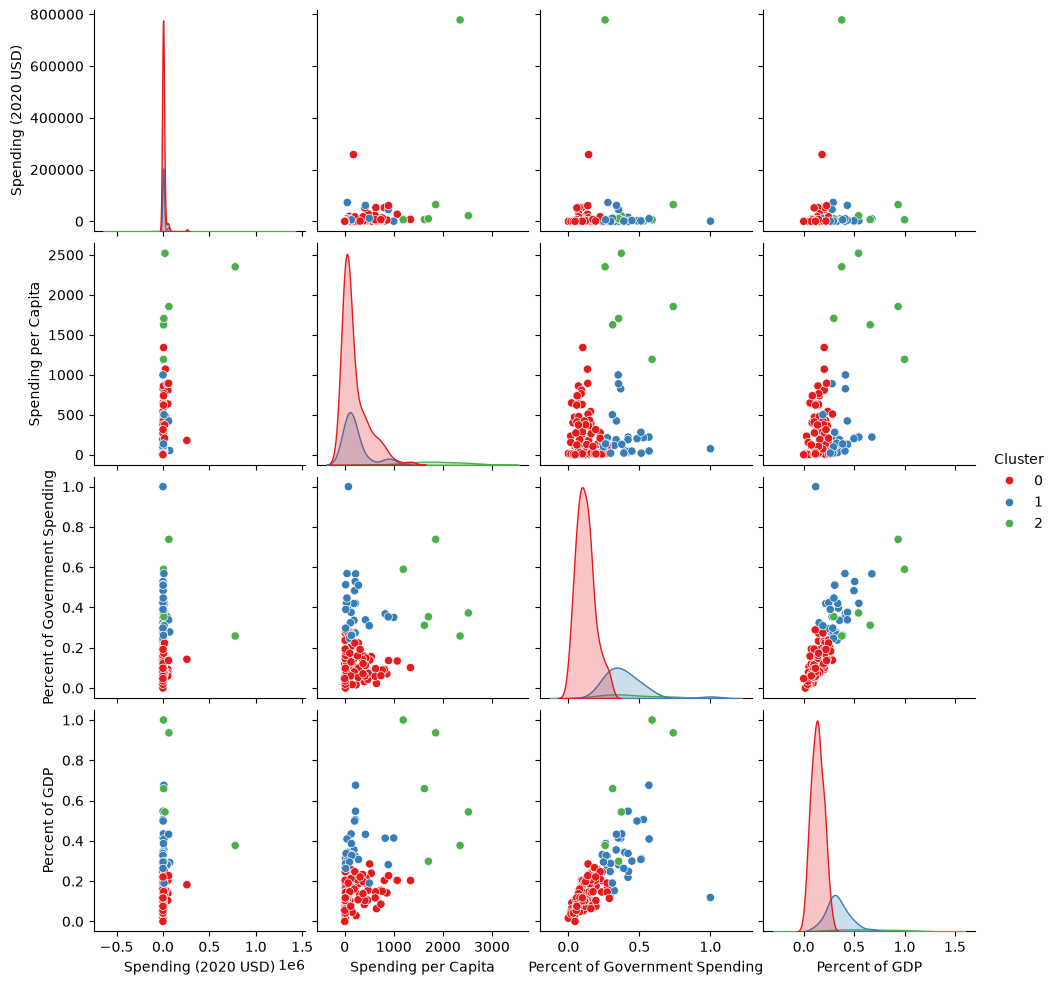

In [ ]:
# Q2 - 4: using clustering with all 4 variables - making plot with all 4 variables and clustering
model = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, random_state = 0)
model = model.fit(X4)
df['Cluster'] = model.labels_
display(df['Cluster'].value_counts())

sns.pairplot(data = df, vars = cols4, hue = 'Cluster', palette = 'Set1')

display(df.groupby('Cluster')[cols4].describe().T)
display(df.loc[df['Country'] == 'United States of America'])

# It seems that the clusters are pretty similar to what you would expect with the combination between all 4 values. 
# Based on the pairplots, the clusters are distinguishable in basically all of the plots. The only plot that seems that the clusters are not really different are the ones that have to do with spending (2020 USD)
# This shows that the spending is hard to cluster on, but the other variables create clusters. 
# Clusters have 111/31/6 countries. The US lands in the 6-country cluster with the highest Percent of GDP (mean ≈0.64 scaled), versus alone in Part 2 and the middle cluster in Part 3. The pairplot shows the clusters separate well on the three non-total-spending variables but overlap on Spending (2020 USD), which is because only the US and one other country have non-trivial values after min-max scaling.

# Q2 - 5: useful patterns
# The clustering did show useful a useful pattern. It basically clustered the countries based on their spending and countries with a high military burden and high per capita spending.
# Using this method for spending analysis is helpful when looking at specific spending (government and per captia), but not helpful when looking at the overall spending.
# This is due to an outlier and a large limitation to this model is that an outlier can really influence the results. 
# This is shown with the spending (2020 USD) variable because the outlier really influenced the scaling leading to a lack of relationship shown.
# The real problem is that spending is extremely right-skewed, so min-max scaling lets the US dominate. A log transform before scaling is the standard fix.



### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Most of the improvements that the AI suggested were cosmetic to make the graphs look better. I honestly did a pretty good job on the bulk of what they questions were asking for. Although, I will say that the changes that AI asked me to make did help convey the clusters and what they meant way better than I did the first time. AI does have some limitations and makes suggestions that just do not have to do with what the question is asking for. It is important to keep a look out for those suggestions because it adds unnecessary work to the document. I verified the final solution by going through it line by line and making sure there were no errors that I could see. Overall, I think it is really important to do the work on your own and then use AI as a check because that is the best way to learn. I sat with the material and had to really understand what was happening, but if we could have used AI on the first part then I can guarantee that I would not truly understand the concept.